In [52]:
#Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, kruskal
from statsmodels.stats.multitest import multipletests
from astropy.timeseries import LombScargle

In [53]:
ruta = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Parámetros para análisis de Antares\Resultados perfiles halpha útiles 2018-2026.xlsx"
datos = pd.read_excel(ruta)
datos

,Época,Componente,Centro [Å],z,Velocidad obs. [km/s],Velocidad heliocéntrica [km/s],Profundidad / Altura,FWHM [Å],EW [Å],Archivo
0,Julio 24-2018,Emisión Azul Hα,6561.874,-0.000140,-42.83,-65.66,0.10,0.68,0.08,2018-2019
1,Julio 24-2018,Absorción Hα,6562.893,0.000012,3.68,-19.15,0.80,1.08,0.92,2018-2019
2,Julio 24-2018,Absorción Cobalto,6563.829,0.000066,19.71,-3.12,0.56,0.94,0.62,2018-2019
3,Julio 27-2018,Emisión Azul Hα,6561.847,-0.000150,-44.10,-67.97,0.14,0.95,0.17,2018-2019
4,Julio 27-2018,Absorción Hα,6562.896,0.000013,3.82,-20.05,0.79,1.07,0.91,2018-2019
...,...,...,...,...,...,...,...,...,...,...
130,Septiembre 29-2026,Absorción Hα,6562.719,-0.000014,-4.23,-30.81,0.79,1.61,1.39,2024-2026
131,Septiembre 29-2026,Absorción Cobalto,6563.856,0.000070,20.95,-5.63,0.55,1.14,0.77,2024-2026
132,Octubre 16-2026,Emisión Azul Hα,6561.934,-0.000130,-40.10,-61.71,0.65,1.05,0.86,2024-2026
133,Octubre 16-2026,Absorción Hα,6562.575,-0.000036,-10.83,-32.44,0.82,1.61,1.44,2024-2026


In [54]:
meses = {'Julio':7,'Agosto':8,'Septiembre':9,'Octubre':10,'Noviembre':11,'Diciembre':12}

def parsear_fecha(s):

    mes, resto = s.strip().split(' ')
    dia, anio = resto.split('-')
    return pd.Timestamp(year=int(anio), month=meses[mes.capitalize()], day=int(dia))

datos = datos.copy()
datos['Fecha'] = datos['Época'].apply(parsear_fecha)
datos['Año'] = datos['Fecha'].dt.year
datos['t'] = datos['Fecha'].dt.year + (datos['Fecha'].dt.dayofyear - 1) / 365.25

datos = datos.rename(columns={
    'Velocidad heliocéntrica [km/s]': 'V_helio',
    'Profundidad / Altura': 'Amp',
    'FWHM [Å]': 'FWHM',
    'EW [Å]': 'EW',})
    #'Centro [Å]': 'Centro'})

# Nombres cortos de componentes

datos['Comp'] = datos['Componente'].replace({'Absorción Hα': 'AbsHα', 'Emisión Azul Hα': 'EmiHα', 'Absorción Cobalto': 'Co'})
print(datos['Comp'].unique())

variables = ['V_helio', 'Amp', 'FWHM', 'EW']

['EmiHα' 'AbsHα' 'Co']


              var1            var2       rho             p         p_FDR
52           EW_Co         FWHM_Co  0.965175  1.138328e-26  1.195244e-24
29       Amp_EmiHα        EW_EmiHα  0.961036  1.221387e-25  6.412281e-24
38       Amp_EmiHα  ΔV_EmiHα_AbsHα  0.940622  8.544006e-22  2.990402e-20
68        EW_EmiHα  ΔV_EmiHα_AbsHα  0.935430  4.916970e-21  1.290705e-19
100  V_helio_EmiHα     ΔV_EmiHα_Co  0.914493  1.666667e-18  3.500000e-17
..             ...             ...       ...           ...           ...
42        EW_AbsHα         FWHM_Co  0.362465  1.440843e-02  2.564213e-02
66        EW_EmiHα     ΔV_AbsHα_Co -0.358417  1.562326e-02  2.734071e-02
54           EW_Co   V_helio_AbsHα -0.350987  1.807930e-02  3.112011e-02
7        Amp_AbsHα      FWHM_EmiHα -0.347231  1.944018e-02  3.292289e-02
72      FWHM_AbsHα      V_helio_Co -0.330033  2.682349e-02  4.470582e-02

[63 rows x 5 columns]


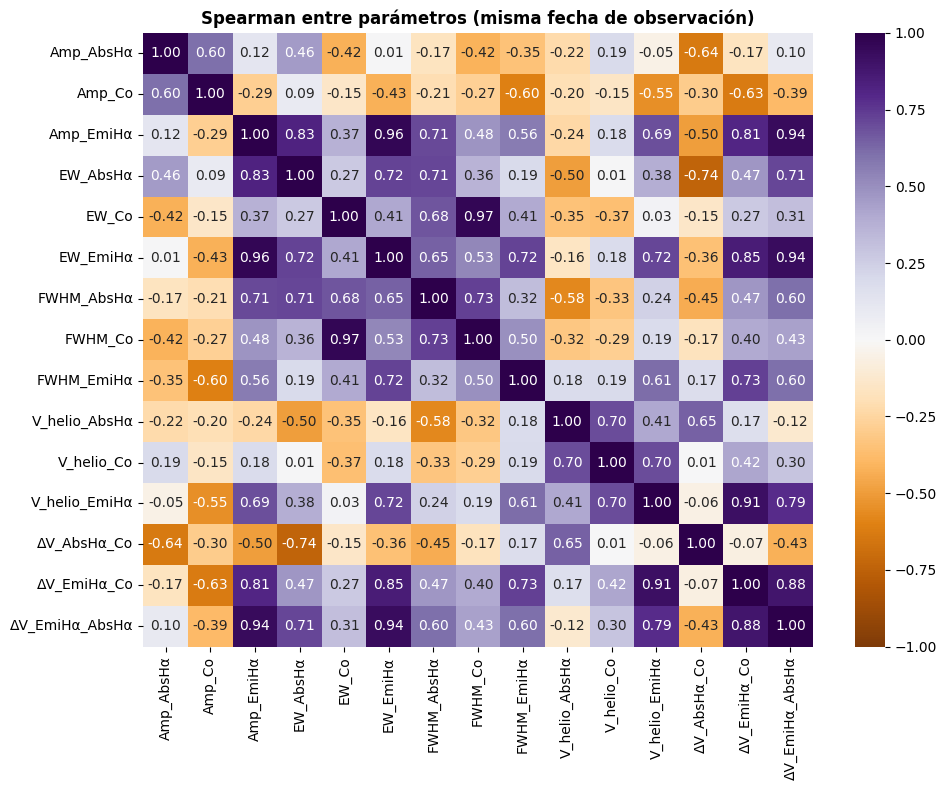

In [56]:
# Una fila por época
ancho = datos.pivot_table(index=['Fecha', 'Año', 't'], columns='Comp', values=variables)
ancho.columns = [f'{v}_{c}' for v, c in ancho.columns]
ancho = ancho.reset_index().sort_values('t')

# Desfase entre la VR de  Abs Hα y Co I
if {'V_helio_AbsHα', 'V_helio_Co'} <= set(ancho.columns):
    ancho['ΔV_AbsHα_Co'] = ancho['V_helio_AbsHα'] - ancho['V_helio_Co']

# Desfase entre la VR de Emi Hα y Co I
if {'V_helio_EmiHα', 'V_helio_Co'} <= set(ancho.columns):
    ancho['ΔV_EmiHα_Co'] = ancho['V_helio_EmiHα'] - ancho['V_helio_Co']

# Desfase entre la VR de las componentes de Emisión y Absorción de Hα
if {'V_helio_EmiHα', 'V_helio_AbsHα'} <= set(ancho.columns):
    ancho['ΔV_EmiHα_AbsHα'] = ancho['V_helio_EmiHα'] - ancho['V_helio_AbsHα']

# Análisis estadístico de Spearman entre parámetros de la misma época
cols = [c for c in ancho.columns if c not in ['Fecha', 'Año', 't']]

def spearman_matriz(d, cols):
    rho = pd.DataFrame(index=cols, columns=cols, dtype=float)
    pv = rho.copy()
    for a in cols:
        for b in cols:
            if a == b:
                rho.loc[a, b] = 1.0
                continue
            sub = d[[a, b]].dropna()
            if len(sub) >= 5:
                r, p = spearmanr(sub[a], sub[b])
                rho.loc[a, b], pv.loc[a, b] = r, p
    return rho, pv

rho, pv = spearman_matriz(ancho, cols)

# Corrección por comparaciones múltiples (FDR) sobre el triángulo superior
iu = np.triu_indices(len(cols), k=1)
pvals = pv.values[iu]
ok = ~np.isnan(pvals)
p_fdr = np.full_like(pvals, np.nan)
p_fdr[ok] = multipletests(pvals[ok], method='fdr_bh')[1]

tabla = pd.DataFrame({'var1': np.array(cols)[iu[0]], 'var2': np.array(cols)[iu[1]],
                      'rho': rho.values[iu], 'p': pvals, 'p_FDR': p_fdr})
tabla = tabla.dropna().sort_values('p')
print(tabla[tabla['p_FDR'] < 0.05])   # Riesgo de falsos positivos < 5%

plt.figure(figsize=(10, 8))
sns.heatmap(rho.astype(float), annot=True, fmt='.2f', cmap='PuOr', vmin=-1, vmax=1)
plt.title('Spearman entre parámetros (misma fecha de observación)', fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

          variable   n    ρ vs t             p         p_FDR
7          FWHM_Co  45  0.786995  1.452148e-10  2.178222e-09
6       FWHM_AbsHα  45  0.741241  5.765772e-09  4.324329e-08
4            EW_Co  45  0.681654  2.536736e-07  1.268368e-06
5         EW_EmiHα  45  0.670029  4.799836e-07  1.799938e-06
2        Amp_EmiHα  45  0.611190  8.214147e-06  2.464244e-05
8       FWHM_EmiHα  45  0.573773  3.780782e-05  9.451955e-05
1           Amp_Co  45 -0.538100  1.375901e-04  2.761802e-04
13     ΔV_EmiHα_Co  45  0.536100  1.472961e-04  2.761802e-04
14  ΔV_EmiHα_AbsHα  45  0.523188  2.264400e-04  3.774000e-04
0        Amp_AbsHα  45 -0.497048  5.139911e-04  7.709866e-04
3         EW_AbsHα  45  0.410285  5.122310e-03  6.984968e-03
11   V_helio_EmiHα  45  0.333070  2.537215e-02  3.171518e-02
10      V_helio_Co  45 -0.272584  7.005324e-02  8.083066e-02
9    V_helio_AbsHα  45 -0.250198  9.739244e-02  1.043490e-01
12     ΔV_AbsHα_Co  45 -0.043347  7.773857e-01  7.773857e-01


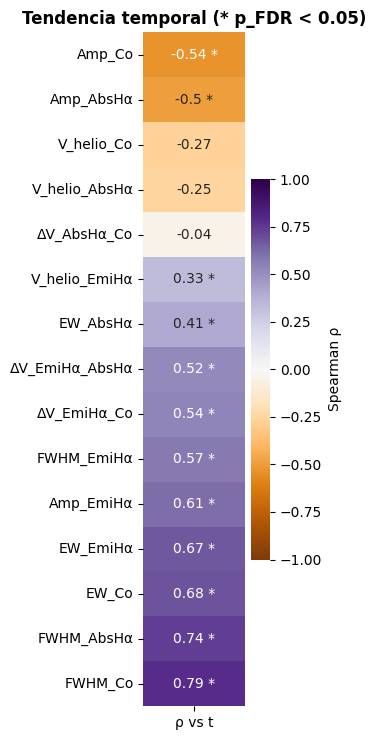

In [ ]:
# Tendencia temporal de cada parámetro (Spearman vs t)

res_t = []
for c in cols:
    sub = ancho[['t', c]].dropna()
    if len(sub) >= 5:
        r, p = spearmanr(sub['t'], sub[c])
        res_t.append((c, len(sub), r, p))

res_t = pd.DataFrame(res_t, columns=['variable', 'n', 'ρ vs t', 'p'])
res_t['p_FDR'] = multipletests(res_t['p'], method='fdr_bh')[1]
print(res_t.sort_values('p'))

# Orden por ρ y marca de significancia según p_FDR
tab = res_t.set_index('variable').sort_values('ρ vs t')
etiquetas = tab['ρ vs t'].round(2).astype(str) + np.where(tab['p_FDR'] < 0.05, ' *', '')

plt.figure(figsize=(3.5, 0.4 * len(tab) + 1.5))
sns.heatmap(tab[['ρ vs t']], annot=etiquetas.to_frame(), fmt='',
            cmap='PuOr', vmin=-1, vmax=1, cbar_kws={'label': 'Spearman ρ'})
plt.title('Tendencia temporal (* p_FDR < 0.05)', fontsize=12, fontweight="bold")
plt.ylabel('')
plt.tight_layout(); plt.show()

In [ ]:

# Kruskal-Wallis por año (mínimo 3 espectros por año)

res_kw = []
for c in cols:
    grupos = [g[c].dropna().values for _, g in ancho.groupby('Año')]
    grupos = [g for g in grupos if len(g) >= 3]
    if len(grupos) >= 2:
        H, p = kruskal(*grupos)
        res_kw.append((c, len(grupos), H, p))
res_kw = pd.DataFrame(res_kw, columns=['variable', 'n_años', 'H', 'p'])
res_kw['p_FDR'] = multipletests(res_kw['p'], method='fdr_bh')[1]
print(res_kw.sort_values('p'))

# Mediana (y rango intercuartílico) por año
med = ancho.groupby('Año')[cols].agg(['median', lambda x: x.quantile(.75) - x.quantile(.25), 'count'])
print(med)

# ---------- 6. Gráficas de evolución temporal ----------
fig, axs = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for ax, v in zip(axs.ravel(), variables):
    for comp, m in [('AbsHa', 'o'), ('EmiHa', 's'), ('Co', '^')]:
        c = f'{v}_{comp}'
        if c in ancho:
            ax.plot(ancho['t'], ancho[c], m, label=comp, alpha=.8)
    ax.set_ylabel(v); ax.legend()
axs[1, 0].set_xlabel('Año'); axs[1, 1].set_xlabel('Año')
plt.tight_layout(); plt.show()

# ---------- 7. Periodograma Lomb-Scargle (velocidades) ----------
fig, ax = plt.subplots(figsize=(9, 4))
for c in ['V_helio_Co', 'V_helio_AbsHa', 'dV_AbsHa_Co']:
    if c in ancho:
        sub = ancho[['t', c]].dropna()
        if len(sub) > 10:
            freq, power = LombScargle(sub['t'], sub[c]).autopower(
                minimum_frequency=1/(sub['t'].max() - sub['t'].min()),
                maximum_frequency=2, samples_per_peak=10)
            ax.plot(1/freq, power, label=c)
            print(c, 'periodo del pico principal: %.2f años' % (1/freq[np.argmax(power)]))
ax.set_xscale('log'); ax.set_xlabel('Periodo [años]'); ax.set_ylabel('Potencia'); ax.legend()
plt.tight_layout(); plt.show()

# ---------- 8. Correlación con desfase (dV vs. V del Cobalto) ----------
# Interpolamos la serie del Cobalto y buscamos el retardo que maximiza Spearman con dV
if 'dV_AbsHa_Co' in ancho:
    s = ancho[['t', 'V_helio_Co', 'dV_AbsHa_Co']].dropna()
    retardos = np.arange(0, 3.01, 0.1)  # años; ajusta según tu ciclo
    out = []
    for lag in retardos:
        vco = np.interp(s['t'] - lag, s['t'], s['V_helio_Co'])
        mask = (s['t'] - lag) >= s['t'].min()
        if mask.sum() >= 8:
            r, p = spearmanr(vco[mask], s['dV_AbsHa_Co'][mask])
            out.append((lag, r, p, mask.sum()))
    out = pd.DataFrame(out, columns=['lag_años', 'rho', 'p', 'n'])
    print(out.loc[out['rho'].abs().idxmax()])
    plt.plot(out['lag_años'], out['rho']); plt.xlabel('Retardo [años]'); plt.ylabel('Spearman ρ')
    plt.show()